# UN Noon Briefings — Sentiment & Tone Visualization

This is a **separate visualization notebook**. It reads existing sentiment and tone classifications from the project's database; it does not call the LLM or create new analysis runs.

Run from the project root (`E:\correlaid-mentoring-project`) using the same Pipenv environment as the analysis notebook.

Before running this notebook,run the following notebook and enusre that data is stored on the database E:\correlaid-mentoring-project\app\briefings.db

The sentiment and tone analysis was performed in the
[sentiment_analysis_tone1.2_fixed.ipynb](sentiment_analysis_tone1.2_fixed.ipynb)
notebook.




## 1. Imports and database connection


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from un_llm_analysis.config import BRIEFINGS_DB_PATH
from un_llm_analysis.database import (
    get_db_connection,
    get_latest_analysis_run,
    get_sentiment_results,
)


print(f"Database path: {BRIEFINGS_DB_PATH}")

Database path: E:\correlaid-mentoring-project\app\briefings.db


## 2. Select an analysis run

The database may contain multiple runs. By default, this selects the latest `analysis_id` that has successful classifications. To visualize a specific run, set `ANALYSIS_ID` to its ID instead of `None`.

In [26]:
ANALYSIS_NAME = "UN briefing sentiment and tone analysis"

with get_db_connection(BRIEFINGS_DB_PATH) as conn:
    ANALYSIS_ID = get_latest_analysis_run(
        conn,
        ANALYSIS_NAME,
    )

    if ANALYSIS_ID is None:
        raise ValueError(
            "No analysis run found. Run the sentiment and tone analysis first."
        )

    results_df = get_sentiment_results(
        conn,
        ANALYSIS_ID,
    )

print(f"Visualizing analysis_id={ANALYSIS_ID}")
print(f"Total result rows: {len(results_df)}")

Visualizing analysis_id=20
Total result rows: 88


## 3. Load classifications and briefing dates from the database

The query joins `sentiment_analysis` to `briefing` using `briefing_id`, so the charts can show results over time. It only loads rows for the selected run.

In [27]:


if results_df.empty:
    raise ValueError(
        f"No rows found for analysis_id={ANALYSIS_ID}."
    )

results_df["briefing_date"] = pd.to_datetime(
    results_df["briefing_date"],
    errors="coerce",
)

successful = results_df.loc[
    results_df["status"] == "success"
].copy()

print(f"Rows loaded: {len(results_df):,}")
print(f"Successful classifications: {len(successful):,}")
print(
    f"Failed classifications: "
    f"{(results_df['status'] != 'success').sum():,}"
)

display(results_df.head())


Rows loaded: 88
Successful classifications: 88
Failed classifications: 0


,analysis_result_id,analysis_id,briefing_id,section_id,briefing_date,section_order,title,section_text,sentiment,tone,status,error_message,created_at
0,1627,20,20260901,2026090101,2026-09-01,1,TODAY’S BRIFING,"At 12:30 p.m., Jérôme Bonnafont, the Permanent...",Positive,Neutral/Informational,success,None,2026-10-13T22:42:05.110762
1,1628,20,20260901,2026090102,2026-09-01,2,TOMORROW’S GUEST,"Inger Andersen, the Executive Director of UNEP...",Positive,Neutral/Informational,success,None,2026-10-13T22:42:09.665759
2,1629,20,20260901,2026090103,2026-09-01,3,TRAVELS/KYRGYZSTAN,The Secretary-General today remains in Bishkek...,Positive,Constructive,success,None,2026-10-13T22:42:20.716983
3,1630,20,20260901,2026090104,2026-09-01,4,DEPUTY SECRETARY-GENERAL TRAVELS,"Our Deputy Secretary-General, Amina Mohammed, ...",Positive,Neutral/Informational,success,None,2026-10-13T22:42:27.549118
4,1631,20,20260901,2026090105,2026-09-01,5,NEPAL,UN colleagues say that the response to last we...,Neutral,Concerned,success,None,2026-10-13T22:42:47.090841


## 4. Classification status

Check whether the selected run has errors before interpreting its charts.

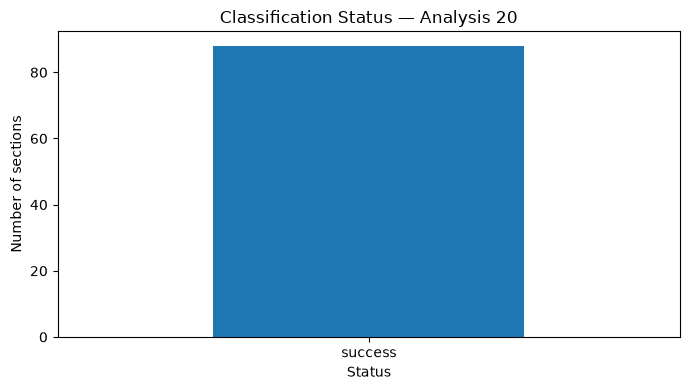

In [28]:
status_counts = results_df["status"].fillna("Missing status").value_counts()
ax = status_counts.plot(kind="bar", figsize=(7, 4))
ax.set_title(f"Classification Status — Analysis {ANALYSIS_ID}")
ax.set_xlabel("Status")
ax.set_ylabel("Number of sections")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 5. Sentiment distribution

Only successful classifications are included.

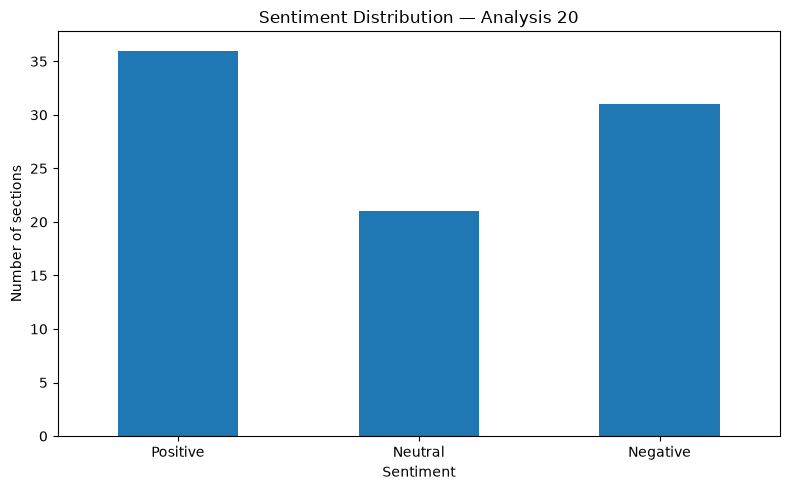

,count
sentiment,
Positive,36
Neutral,21
Negative,31


In [29]:
sentiment_order = ["Positive", "Neutral", "Negative"]
sentiment_counts = successful["sentiment"].value_counts().reindex(sentiment_order, fill_value=0)

ax = sentiment_counts.plot(kind="bar", figsize=(8, 5))
ax.set_title(f"Sentiment Distribution — Analysis {ANALYSIS_ID}")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of sections")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

display(sentiment_counts.rename("count").to_frame())

## 6. Tone distribution

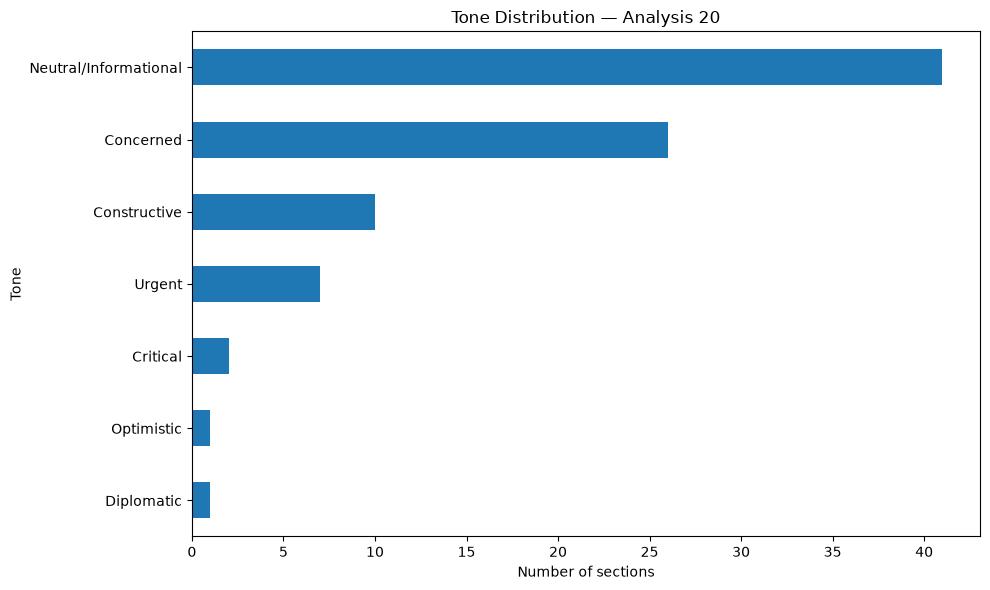

,count
tone,
Neutral/Informational,41
Concerned,26
Constructive,10
Urgent,7
Critical,2
Optimistic,1
Diplomatic,1


In [30]:
tone_order = [
    "Diplomatic", "Concerned", "Critical", "Urgent",
    "Optimistic", "Neutral/Informational", "Constructive"
]
tone_counts = successful["tone"].value_counts().reindex(tone_order, fill_value=0).sort_values()

ax = tone_counts.plot(kind="barh", figsize=(10, 6))
ax.set_title(f"Tone Distribution — Analysis {ANALYSIS_ID}")
ax.set_xlabel("Number of sections")
ax.set_ylabel("Tone")
plt.tight_layout()
plt.show()

display(tone_counts.sort_values(ascending=False).rename("count").to_frame())

## 7. Sentiment and tone relationship

A crosstab and stacked bar chart show which tones occur with each sentiment.

tone,Concerned,Constructive,Critical,Diplomatic,Neutral/Informational,Optimistic,Urgent
sentiment,,,,,,,
Positive,0,10,0,1,22,1,2
Neutral,3,0,0,0,18,0,0
Negative,23,0,2,0,1,0,5


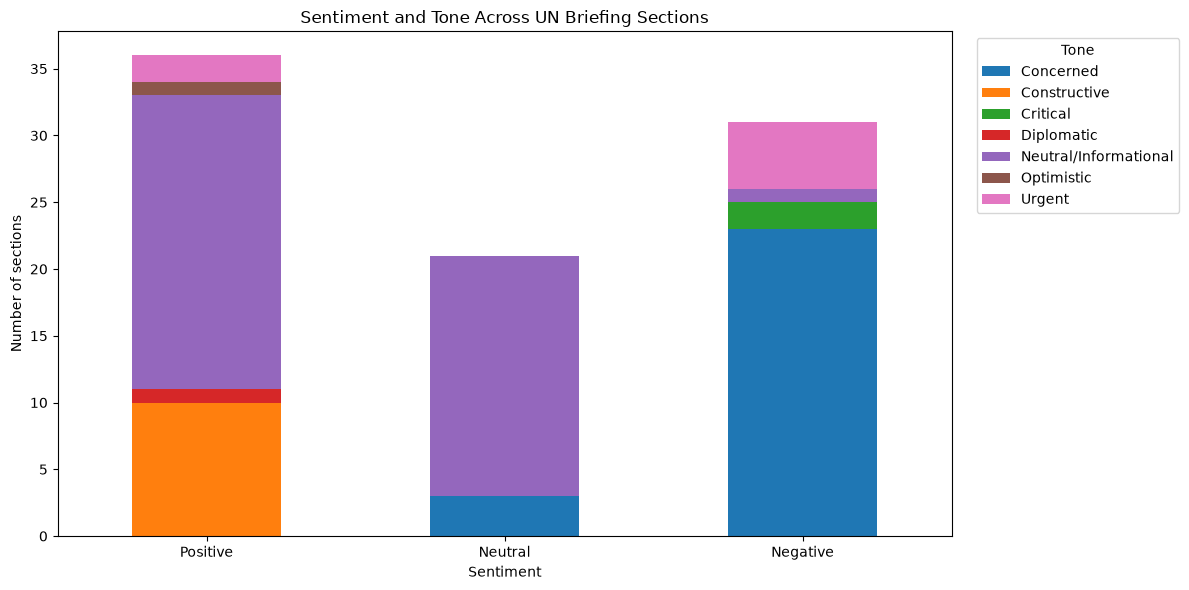

In [31]:
cross_tab = pd.crosstab(successful["sentiment"], successful["tone"])
cross_tab = cross_tab.reindex(index=sentiment_order, fill_value=0)
display(cross_tab)

ax = cross_tab.plot(kind="bar", stacked=True, figsize=(12, 6))
ax.set_title("Sentiment and Tone Across UN Briefing Sections")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of sections")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Tone", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 8.Sentiment over time — last 6 months


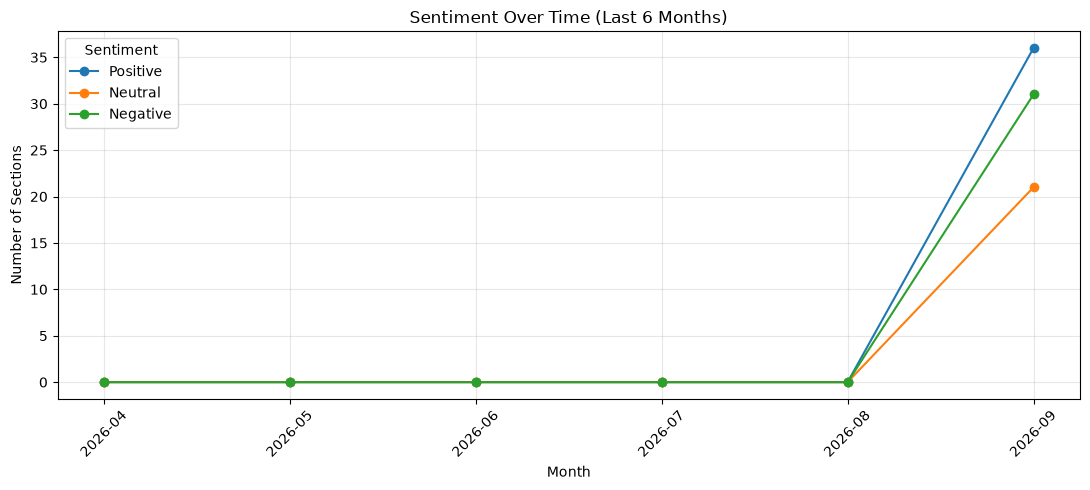

In [37]:

import matplotlib.pyplot as plt
# Define the order in which sentiment categories should appear
# in the chart and the monthly summary table.
sentiment_order = ["Positive", "Neutral", "Negative"]

# Find the most recent briefing date in the successful
# sentiment analysis results. This date determines the end
# of the six-month analysis period.
latest_date = successful["briefing_date"].max()
# Stop execution if no valid briefing date is available.
if pd.isna(latest_date):
    raise ValueError("No valid briefing dates are available.")
# Determine the six calendar months to analyse.
# Convert the latest date to a monthly period, then subtract
# five months to obtain the first month.
# Example: October 2026 -> May 2026 through October 2026.
latest_month = latest_date.to_period("M")
first_month = latest_month - 5
# Create the last_6_months DataFrame.
# Keep all successfully analysed sections whose briefing date
# falls on or after the first day of the first month.
# This includes records up to the latest available briefing date.
last_6_months = successful[
    successful["briefing_date"] >= first_month.start_time
].copy()
# Calculate the number of sections for each sentiment
# in each month.
#
# a) groupby() group records by briefing month and sentiment.
# b) size() count the number of records in each group.
# c) unstack() convert sentiment categories into separate columns.
# d) fill_value=0 assign zero where a month has no records
#    for a particular sentiment.
# e) reindex() enforce a consistent sentiment column order
#    and include categories missing from the data.
sentiment_monthly = (
    last_6_months.groupby(
        [last_6_months["briefing_date"].dt.to_period("M"), "sentiment"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=sentiment_order, fill_value=0)
)

# Generate a continuous sequence of six calendar months.
# Subtracting five months from the latest month gives six months
# when both the starting and ending months are included.
months = pd.period_range(
    start=last_6_months["briefing_date"].max().to_period("M") - 5,
    end=last_6_months["briefing_date"].max().to_period("M"),
    freq="M",
)
# Add any missing months to the summary table.
# If a month has no records, its sentiment counts are set to zero.
sentiment_monthly = sentiment_monthly.reindex(months, fill_value=0)
# Convert monthly periods into strings for readable chart labels.
sentiment_monthly.index = sentiment_monthly.index.astype(str)
# Plot the monthly sentiment counts.
# Each line represents one sentiment category.
# Each point represents the number of sections classified
# with that sentiment in the corresponding month.
ax = sentiment_monthly.plot(
    kind="line",
    marker="o",
    figsize=(11, 5),
)

ax.set_title("Sentiment Over Time (Last 6 Months)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Sections")
ax.legend(title="Sentiment")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 9.Tone over time — last 6 months

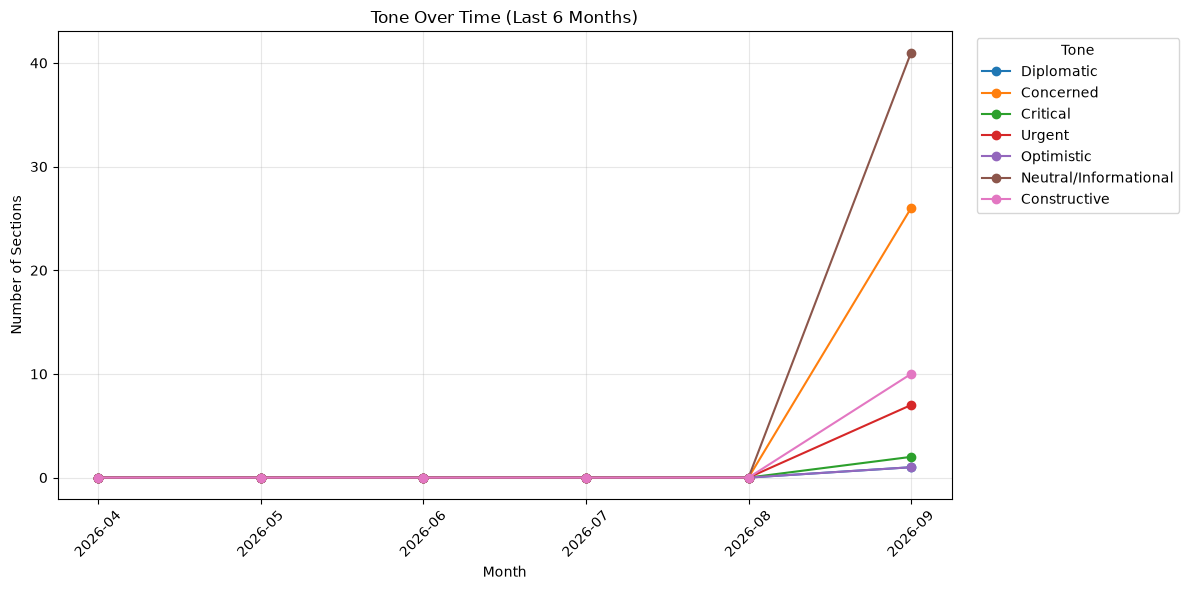

In [39]:

tone_order = [
    "Diplomatic",
    "Concerned",
    "Critical",
    "Urgent",
    "Optimistic",
    "Neutral/Informational",
    "Constructive",
]
# Here use the same logic as in section 8
tone_monthly = (
    last_6_months.groupby(
        [last_6_months["briefing_date"].dt.to_period("M"), "tone"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=tone_order, fill_value=0)
)

tone_monthly = tone_monthly.reindex(months, fill_value=0)
tone_monthly.index = tone_monthly.index.astype(str)

ax = tone_monthly.plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
)

ax.set_title("Tone Over Time (Last 6 Months)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Sections")
ax.legend(title="Tone", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Observations

Positive sentiment: Most sections have a Neutral/Informational tone. Some sections have a Constructive tone.

Neutral sentiment: Most sections also have a Neutral/Informational tone.

Negative sentiment: Most sections have a Concerned tone. A few sections have an Urgent or Critical tone.

Overall, Neutral/Informational is the most common tone for positive and neutral sections, while Concerned is the most common tone for negative sections.

This analysis helps us understand how the UN communicates about different issues in its daily briefings.